# Quantitative Audit, Time-Series Modeling and Forecasting of the PONAX Fund

## Objective

This notebook combines the two parts of the study of the PONAX bond fund (PIMCO Income A), from February 2015 to December 2024:

- **Part I — Quantitative audit and style analysis**: which factors explain the fund's excess returns? We compare the Fama-French 3-factor model, a bond model (Mkt-RF, TERM, DEF) and a combined model, then validate the retained model with a set of diagnostic tests.
- **Part II — Time-series modeling, backtesting and forecasting**: can the fund's past returns forecast its excess return better than a naive model (historical mean)? We test the bond model residuals (Ljung-Box), calibrate an ARMA model and compare its forecasts with the twelve months of 2024.

# 1. Importing libraries

In [42]:
import itertools
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.stats.diagnostic as smd

from scipy.stats import jarque_bera
from scipy.stats import norm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Part I — Quantitative audit and style analysis

# 2. Data collection

### 2.1 PONAX fund data

Study period: January 2015 to December 2024 inclusive.

In [43]:
ponax_prices = yf.download(
    "PONAX",                    # Ticker of the PONAX fund on Yahoo Finance
    start = "2015-01-01",       # Start of the study period
    end = "2025-01-01",         # Exclusive end date: includes December 2024
    interval = "1mo",           # Monthly frequency
    auto_adjust = True,         # Prices adjusted for distributions and other corporate actions
    progress = False            # Disables the progress bar
)["Close"]                      # Keep only the closing prices

### 2.2 Fama-French factors

In [44]:
ff3 = pd.read_csv(
    "data/F-F_Research_Data_Factors.csv",
    skiprows = 3,
    index_col = 0
)

### 2.3 Moody's and US Treasury yield series

In [45]:
baa_yield = pd.read_csv(
    "data/DBAA.csv",
    parse_dates = ["observation_date"],
    index_col = "observation_date"
)

yield_10y = pd.read_csv(
    "data/DGS10.csv",
    parse_dates = ["observation_date"],
    index_col = "observation_date"
)

yield_3m = pd.read_csv(
    "data/DTB3.csv",
    parse_dates = ["observation_date"],
    index_col = "observation_date"
)

# 3. Data preparation and variable construction

### 3.1 Harmonizing names, dates and units

In [46]:
# Rename the columns of each DataFrame
ponax_prices.columns = ["PONAX"]
baa_yield.columns = ["BAA"]
yield_10y.columns = ["DGS10"]
yield_3m.columns = ["DTB3"]

# Keep only the monthly observations
ff3 = ff3[ff3.index.astype(str).str.match(r"^\d{6}$")]

# Convert the columns to numeric values
ff3 = ff3.apply(pd.to_numeric, errors = "coerce")

# Harmonize the indexes as monthly periods
ff3.index = pd.PeriodIndex(
    ff3.index.astype(str),
    freq = "M"
)

ponax_prices.index = pd.PeriodIndex(
    ponax_prices.index,
    freq = "M"
)

baa_yield.index = pd.PeriodIndex(
    baa_yield.index,
    freq = "M"
)

yield_10y.index = pd.PeriodIndex(
    yield_10y.index,
    freq = "M"
)

yield_3m.index = pd.PeriodIndex(
    yield_3m.index,
    freq = "M"
)

# Select the study period
ff3 = ff3.loc["2015-01":"2024-12"]

# Convert percentages to decimals
baa_yield = baa_yield / 100
yield_10y = yield_10y / 100
yield_3m = yield_3m / 100
ff3 = ff3 / 100

### 3.2 Monthly returns of the PONAX fund

In [47]:
# Monthly log return of the fund
ponax_returns = np.log(ponax_prices / ponax_prices.shift(1)).dropna()
ponax_returns.columns = ["PONAX_Return"]

# Log returns make it easy to aggregate returns over several periods.

### 3.3 Excess returns of the PONAX fund

In [48]:
# Excess return of the fund over the risk-free rate (RF) from the Fama-French data
excess_return_ponax = ponax_returns.sub(ff3["RF"], axis=0)
excess_return_ponax.columns = ["Excess_PONAX"]

### 3.4 Monthly changes in yields

In [49]:
def monthly_change(data):
    return data.diff()

# Monthly change in the BAA corporate bond yield
delta_baa = monthly_change(baa_yield)

# Monthly change in the US 10-year yield
delta_10y = monthly_change(yield_10y)

# Monthly change in the US 3-month yield
delta_3m = monthly_change(yield_3m)

### 3.5 TERM factor

In [50]:
# TERM measures the monthly change in the spread between the US 10-year yield and the 3-month yield.
term = pd.DataFrame({
    "TERM": delta_10y["DGS10"] - delta_3m["DTB3"]
})

### 3.6 DEF factor

In [51]:
# DEF measures the monthly change in the spread between the BAA corporate bond yield and the US 10-year Treasury yield.
def_factor = pd.DataFrame({
    "DEF": delta_baa["BAA"] - delta_10y["DGS10"]
})

### 3.7 Merging the data

In [52]:
# Merge all the variables needed for the analysis.

regression_data = pd.concat(
    [
        excess_return_ponax,
        ff3[["Mkt-RF", "SMB", "HML"]],
        term,
        def_factor
    ],
    axis=1,
    join="inner"                            # join="inner" keeps only the dates present in every series.
)

# 4. Preprocessing

### 4.1 Missing values

In [53]:
# Initial number of months
print("Number of months in regression_data before preprocessing:", len(regression_data))

# Identify the observations with at least one missing value
missing_observations = regression_data[
    regression_data.isna().any(axis=1)
]

print(missing_observations)

# Drop the missing values
regression_data = regression_data.dropna()

Number of months in regression_data before preprocessing: 120
         Excess_PONAX  Mkt-RF     SMB     HML  TERM  DEF
2015-01           NaN  -0.031 -0.0059 -0.0345   NaN  NaN


### 4.2 Outliers

In [54]:
# Identify extreme observations with the IQR (interquartile range) method.

# First and third quartiles
Q1 = regression_data.quantile(0.25)
Q3 = regression_data.quantile(0.75)

# Interquartile range
IQR = Q3 - Q1

# Bounds used to flag outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag the outliers
outliers = (
    (regression_data < lower_bound) |
    (regression_data > upper_bound)
)

# Number of outliers per variable
n_outliers = outliers.sum()

print("Number of outliers per variable:")
print(n_outliers)

# Variables flagged as outliers for each date
outlier_variables = outliers.apply(
    lambda row: ", ".join(row[row].index),
    axis=1
)

# Add this information to the table of outlier observations
outlier_observations = regression_data[
    outliers.any(axis=1)
].copy()

outlier_observations["Outlier_variables"] = outlier_variables[
    outliers.any(axis=1)
]

outlier_observations

Number of outliers per variable:
Excess_PONAX    10
Mkt-RF           6
SMB              0
HML              6
TERM             4
DEF              4
dtype: int64


,Excess_PONAX,Mkt-RF,SMB,HML,TERM,DEF,Outlier_variables
2016-03,0.018780,0.0695,0.0075,0.0122,0.0013,-3.200000e-03,DEF
2016-11,-0.001572,0.0486,0.0560,0.0829,0.0026,-5.000000e-04,HML
2018-12,0.005914,-0.0955,-0.0231,-0.0192,-0.0033,2.000000e-03,Mkt-RF
2020-03,-0.084583,-0.1337,-0.0469,-0.1383,0.0060,1.310000e-02,"Excess_PONAX, Mkt-RF, HML, TERM, DEF"
2020-04,0.021862,0.1360,0.0250,-0.0134,-0.0006,5.000000e-04,Mkt-RF
2020-06,0.017565,0.0245,0.0267,-0.0217,0.0003,-3.700000e-03,DEF
2020-11,0.025727,0.1245,0.0581,0.0209,0.0009,-2.200000e-03,Mkt-RF
2022-01,-0.010425,-0.0616,-0.0593,0.1286,0.0020,-1.734723e-18,HML
2022-02,-0.025303,-0.0228,0.0216,0.0306,-0.0001,2.100000e-03,Excess_PONAX
2022-04,-0.027220,-0.0941,-0.0135,0.0618,0.0030,-2.500000e-03,"Excess_PONAX, Mkt-RF"


### 4.3 Final sample check

In [55]:
# Check the time structure of the dataset
print("First observation:", regression_data.index.min())
print("Last observation:", regression_data.index.max())
print("Number of observations:", len(regression_data))

# Check for duplicates in the index
print("Number of duplicates:", regression_data.index.duplicated().sum())

# Check for missing values per variable
print("\nMissing values per variable:")
print(regression_data.isna().sum())

First observation: 2015-02
Last observation: 2024-12
Number of observations: 119
Number of duplicates: 0

Missing values per variable:
Excess_PONAX    0
Mkt-RF          0
SMB             0
HML             0
TERM            0
DEF             0
dtype: int64


# 5. Exploratory analysis

### 5.1 Distribution and normality

#### Histograms vs fitted normal distribution

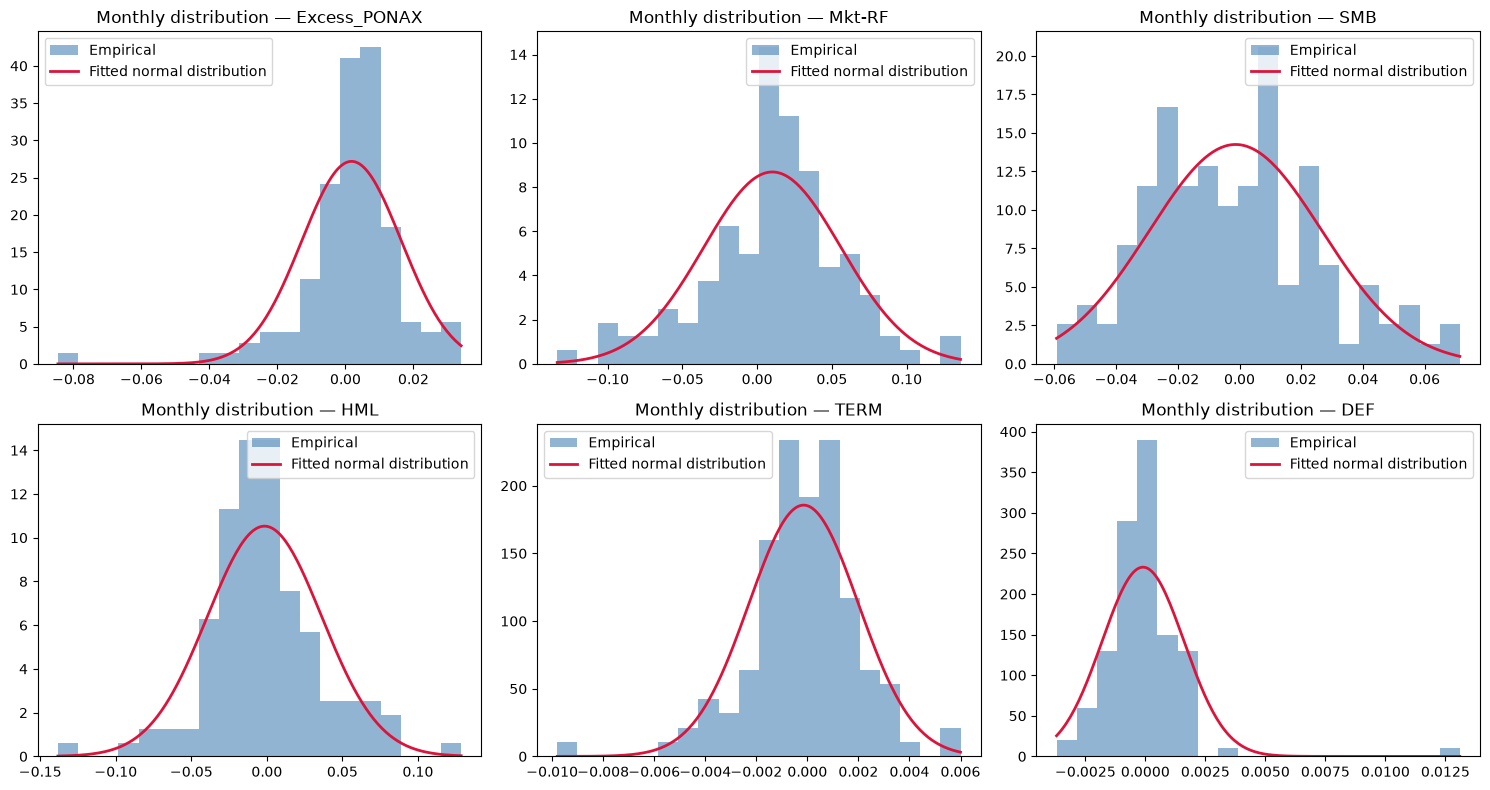

In [56]:
# Histograms vs fitted normal distribution
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flatten(), regression_data.columns):
    series = regression_data[column]
    mu, sigma = series.mean(), series.std()

    ax.hist(series, bins=20, density=True, alpha=0.6,
            color="steelblue", label="Empirical")

    x = np.linspace(series.min(), series.max(), 200)
    ax.plot(x, norm.pdf(x, mu, sigma), color="crimson", lw=2,
            label="Fitted normal distribution")

    ax.set_title(f"Monthly distribution — {column}")
    ax.legend()

plt.tight_layout()

plt.savefig(
    "results/histograms_normality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Descriptive statistics

In [57]:
# Main descriptive statistics for each variable
descriptive_stats = pd.DataFrame({
    "Mean (%)": 100 * regression_data.mean(),               # Average monthly return in percent
    "Std. dev. (%)": 100 * regression_data.std(),           # Monthly volatility in percent
    "Skewness": regression_data.skew(),                     # Asymmetry of the distribution
    "Excess kurtosis": regression_data.kurtosis(),          # Kurtosis in excess of a normal distribution
    "Raw kurtosis": regression_data.kurtosis() + 3          # Total kurtosis; equals 3 for a normal distribution
})

# Jarque-Bera statistic and p-value to assess the normality of each variable
jb = regression_data.apply(
    lambda x: jarque_bera(x)[0]
)

p_values = regression_data.apply(
    lambda x: jarque_bera(x)[1]
)

# Add the normality test results to the descriptive statistics
descriptive_stats["Jarque-Bera"] = jb
descriptive_stats["Jarque-Bera p-value"] = p_values

# Display the results rounded to four decimals
descriptive_stats.round(4)

,Mean (%),Std. dev. (%),Skewness,Excess kurtosis,Raw kurtosis,Jarque-Bera,Jarque-Bera p-value
Excess_PONAX,0.1796,1.4676,-1.9399,9.9633,12.9633,520.2088,0.0000
Mkt-RF,1.0152,4.5936,-0.3560,0.7437,3.7437,4.6293,0.0988
SMB,-0.1270,2.7991,0.4075,-0.1952,2.8048,3.4888,0.1747
HML,-0.1566,3.7893,0.2216,1.9235,4.9235,16.9016,0.0002
TERM,-0.0145,0.2149,-0.5506,3.2997,6.2997,53.9019,0.0000
DEF,-0.0097,0.1711,3.8237,29.2816,32.2816,4174.3718,0.0000


In [58]:
# Descriptive statistics of all the variables used in the regression
regression_data.describe().round(4)

,Excess_PONAX,Mkt-RF,SMB,HML,TERM,DEF
count,119.0000,119.0000,119.0000,119.0000,119.0000,119.0000
mean,0.0018,0.0102,-0.0013,-0.0016,-0.0001,-0.0001
std,0.0147,0.0459,0.0280,0.0379,0.0021,0.0017
min,-0.0846,-0.1337,-0.0593,-0.1383,-0.0098,-0.0037
25%,-0.0043,-0.0155,-0.0232,-0.0215,-0.0012,-0.0010
50%,0.0031,0.0134,-0.0018,-0.0047,-0.0002,-0.0002
75%,0.0083,0.0344,0.0154,0.0170,0.0011,0.0005
max,0.0340,0.1360,0.0714,0.1286,0.0060,0.0131


### 5.3 Correlation matrix

In [59]:
# Correlation matrix of the explanatory variables of the extended model
factors = regression_data[
    ["Mkt-RF", "SMB", "HML", "TERM", "DEF"]
]

factor_corr = factors.corr()
factor_corr.round(3)

,Mkt-RF,SMB,HML,TERM,DEF
Mkt-RF,1.000,0.297,0.026,-0.145,-0.310
SMB,0.297,1.000,0.113,-0.074,-0.218
HML,0.026,0.113,1.000,0.156,-0.286
TERM,-0.145,-0.074,0.156,1.000,-0.022
DEF,-0.310,-0.218,-0.286,-0.022,1.000


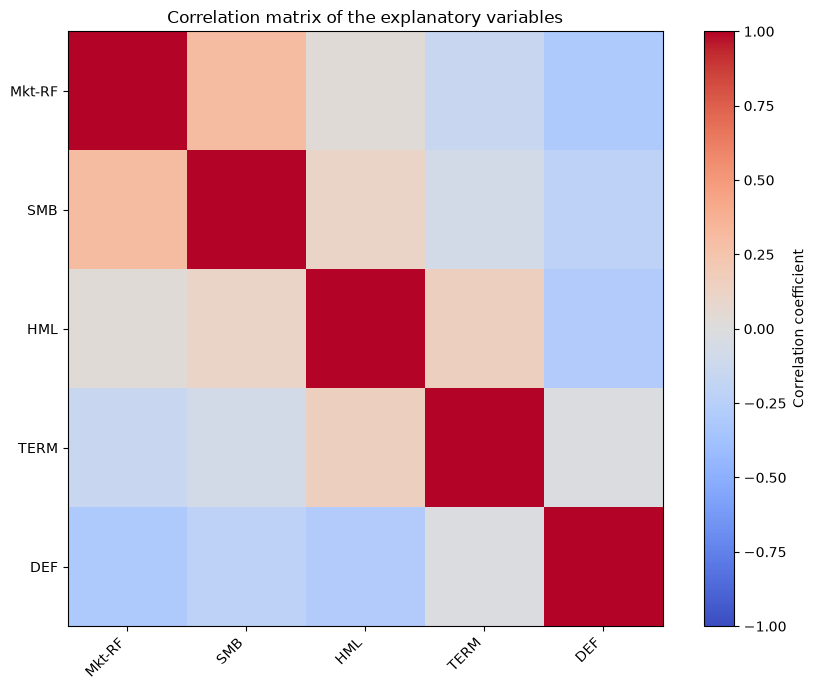

In [60]:
# Heatmap of the correlation matrix
plt.figure(figsize=(9, 7))

plt.imshow(
    factor_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(factor_corr.columns)),
    factor_corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(factor_corr.index)),
    factor_corr.index
)

plt.title("Correlation matrix of the explanatory variables")

plt.tight_layout()

plt.savefig(
    "results/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Modeling

### 6.1 Fama-French 3-factor model

In [61]:
# Select the required variables
ff3_data = regression_data[
    ["Excess_PONAX", "Mkt-RF", "SMB", "HML"]
]

# Dependent variable: excess return of the PONAX fund
Y = ff3_data["Excess_PONAX"]

# Explanatory variables: Fama-French factors
X = ff3_data[["Mkt-RF", "SMB", "HML"]]

# Add a constant to estimate the alpha
X = sm.add_constant(X)

# Estimate the regression
ff3_model = sm.OLS(Y, X).fit()

# Display the results
print(ff3_model.summary())

                            OLS Regression Results                            
Dep. Variable:           Excess_PONAX   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.518
Method:                 Least Squares   F-statistic:                     43.33
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           8.25e-19
Time:                        12:29:50   Log-Likelihood:                 379.01
No. Observations:                 119   AIC:                            -750.0
Df Residuals:                     115   BIC:                            -738.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0003      0.001     -0.351      0.7

### 6.2 Bond model

In [62]:
# Dependent variable: excess return of the PONAX fund
Y = regression_data["Excess_PONAX"]

# Explanatory variables: market factor and bond factors
X = regression_data[["Mkt-RF", "TERM", "DEF"]]

# Add a constant to estimate the alpha
X = sm.add_constant(X)

# Estimate the regression
bond_model = sm.OLS(Y, X).fit()

# Display the results
print(bond_model.summary())

                            OLS Regression Results                            
Dep. Variable:           Excess_PONAX   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     80.64
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           3.72e-28
Time:                        12:29:50   Log-Likelihood:                 401.40
No. Observations:                 119   AIC:                            -794.8
Df Residuals:                     115   BIC:                            -783.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0007      0.001     -0.822      0.4

### 6.3 Combined model

In [63]:
# Dependent variable: excess return of the PONAX fund
Y = regression_data["Excess_PONAX"]

# Explanatory variables: Fama-French factors and bond factors
X = regression_data[["Mkt-RF", "SMB", "HML", "TERM", "DEF"]]

# Add a constant to estimate the alpha
X = sm.add_constant(X)

# Estimate the regression
combined_model = sm.OLS(Y, X).fit()

# Display the results
print(combined_model.summary())

                            OLS Regression Results                            
Dep. Variable:           Excess_PONAX   R-squared:                       0.692
Model:                            OLS   Adj. R-squared:                  0.679
Method:                 Least Squares   F-statistic:                     50.89
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           2.24e-27
Time:                        12:29:50   Log-Likelihood:                 404.17
No. Observations:                 119   AIC:                            -796.3
Df Residuals:                     113   BIC:                            -779.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0006      0.001     -0.710      0.4

# 7. Validation and diagnostics

### 7.1 Linearity: residuals vs fitted values and RESET test

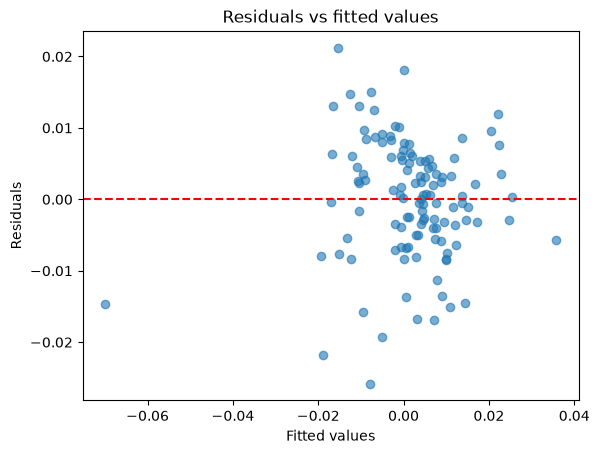

In [64]:
# Residuals vs fitted values plot: the scatter should show no pattern
fig, ax = plt.subplots()
ax.scatter(bond_model.fittedvalues, bond_model.resid, alpha=0.6)
ax.axhline(0, color="red", ls="--")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs fitted values")

plt.savefig(
    "results/residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
# RESET test: H0 = the linear functional form is correctly specified
reset_result = smd.linear_reset(bond_model, power = 3, test_type = "fitted", use_f = True)
print(f"RESET test: F = {reset_result.fvalue:.3f}, p-value = {reset_result.pvalue:.4f}")
print("H0 rejected" if reset_result.pvalue < 0.05 else "H0 not rejected", "at the 5% level.")

RESET test: F = 4.190, p-value = 0.0176
H0 rejected at the 5% level.


### 7.2 Homoskedasticity: Breusch-Pagan test and White correction

In [66]:
# Breusch-Pagan test on the residuals of the bond model
bp_stat, bp_pvalue, _, _ = smd.het_breuschpagan(
    bond_model.resid,
    bond_model.model.exog
)

print("Breusch-Pagan: statistic =", bp_stat)
print("Breusch-Pagan: p-value   =", bp_pvalue)

# Decision
if bp_pvalue < 0.05:
    print("Decision: homoskedasticity is REJECTED -> robust correction needed")
else:
    print("Decision: homoskedasticity is NOT REJECTED -> no correction needed")

# Re-estimate the same model with White robust standard errors
bond_model_robust = bond_model.model.fit(cov_type = "HC1")

# Comparison before / after correction
white_comparison = pd.DataFrame({
    "p (classic OLS)": bond_model.pvalues,
    "p (HC1)": bond_model_robust.pvalues,
    "σ classic": bond_model.bse,
    "σ HC1": bond_model_robust.bse
})

white_comparison.round(5)

Breusch-Pagan: statistic = 20.274929552432976
Breusch-Pagan: p-value   = 0.0001488664942472567
Decision: homoskedasticity is REJECTED -> robust correction needed


,p (classic OLS),p (HC1),σ classic,σ HC1
const,0.41301,0.46825,0.00079,0.00090
Mkt-RF,0.00000,0.00000,0.01802,0.02554
TERM,0.00000,0.00000,0.36630,0.43120
DEF,0.00000,0.00075,0.47873,0.69121


### 7.3 Normality of residuals: Jarque-Bera, histogram and Q-Q plot

In [67]:
# Residuals of the bond model
residuals = bond_model_robust.resid

# Jarque-Bera test on the residuals
jb_residuals, jb_residuals_pvalue = jarque_bera(residuals)

print("Jarque-Bera on the residuals")
print("JB statistic:", jb_residuals)
print("p-value:", jb_residuals_pvalue)

if jb_residuals_pvalue < 0.05:
    print("Decision: normality of the residuals is REJECTED.")
else:
    print("Decision: normality of the residuals is NOT REJECTED.")

Jarque-Bera on the residuals
JB statistic: 4.315973130690375
p-value: 0.1155575545496524
Decision: normality of the residuals is NOT REJECTED.


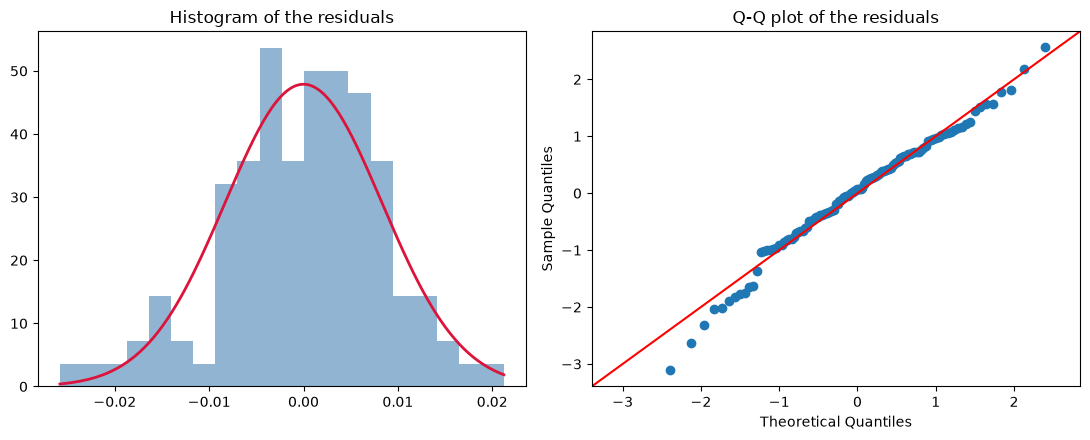

In [68]:
# Histogram of the residuals with fitted normal distribution, and Q-Q plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(bond_model.resid, bins=20, density=True, alpha=0.6, color="steelblue")
mu_r, sigma_r = bond_model.resid.mean(), bond_model.resid.std()
x_grid = np.linspace(bond_model.resid.min(), bond_model.resid.max(), 200)
axes[0].plot(x_grid, norm.pdf(x_grid, mu_r, sigma_r), color="crimson", lw=2)
axes[0].set_title("Histogram of the residuals")

sm.qqplot(bond_model.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of the residuals")

plt.tight_layout()

plt.savefig(
    "results/residuals_normality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.4 Influential points: Cook's distance

Cook's threshold (4/n) = 0.0336
6 potentially influential observation(s):
2018-12    0.1556
2020-03    2.6635
2022-06    0.2109
2022-07    0.0385
2022-08    0.0618
2022-09    0.1212
Freq: M, Name: Cook's distance, dtype: float64


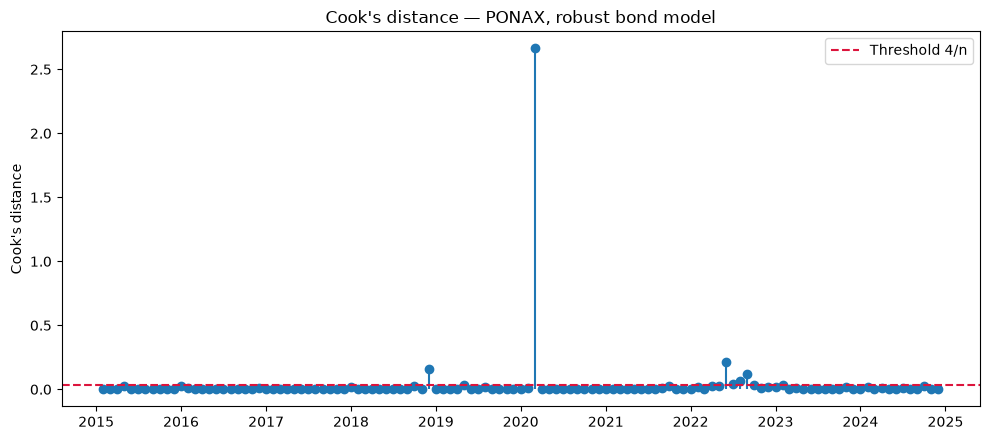

In [69]:
# Cook's distance of each observation, indexed by date
cooks_d = pd.Series(
    bond_model_robust.get_influence().cooks_distance[0],
    index=regression_data.index,
    name="Cook's distance"
)

# Usual threshold 4/n
cook_threshold = 4 / len(regression_data)

# Potentially influential observations
influential_points = cooks_d[cooks_d > cook_threshold]

print(f"Cook's threshold (4/n) = {cook_threshold:.4f}")
print(f"{len(influential_points)} potentially influential observation(s):")
print(influential_points.round(4))

# Plot: the index is in monthly periods, converted to dates for the axis
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stem(cooks_d.index.to_timestamp(), cooks_d.values, basefmt=" ")
ax.axhline(cook_threshold, color="crimson", ls="--", label="Threshold 4/n")
ax.set_ylabel("Cook's distance")
ax.set_title("Cook's distance — PONAX, robust bond model")
ax.legend()

plt.tight_layout()

plt.savefig(
    "results/cook_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.5 Multicollinearity: variance inflation factor (VIF)

In [70]:
# Matrix of the bond model's explanatory variables, with the constant in the first column
X_vif = sm.add_constant(regression_data[["Mkt-RF", "TERM", "DEF"]])

# VIF of each explanatory variable
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index = X_vif.columns[1:],
    name = "VIF"
)

print(vif.round(3))
print("\nUsual warning threshold: VIF > 5")

Mkt-RF    1.135
TERM      1.027
DEF       1.112
Name: VIF, dtype: float64

Usual warning threshold: VIF > 5


### 7.6 Residual autocorrelation: Durbin-Watson and Breusch-Godfrey

In [71]:
# Durbin-Watson (same result as in summary())
dw = durbin_watson(bond_model_robust.resid)
print(f"Durbin-Watson: {dw:.3f}  (close to 2 = no first-order autocorrelation)")

# Breusch-Godfrey with 6 lags
bg_stat, bg_pvalue, _, _ = smd.acorr_breusch_godfrey(bond_model_robust, nlags=6)
print(f"Breusch-Godfrey (6 lags): stat = {bg_stat:.3f}, p-value = {bg_pvalue:.4f}")

if bg_pvalue < 0.05:
    print("=> Autocorrelation detected: consider HAC (Newey-West) standard errors")
    print("   or an explicit time-series model (Part II).")
else:
    print("=> No significant residual autocorrelation at the 5% level.")

Durbin-Watson: 2.049  (close to 2 = no first-order autocorrelation)
Breusch-Godfrey (6 lags): stat = 11.866, p-value = 0.0650
=> No significant residual autocorrelation at the 5% level.


C:\Users\justi\AppData\Local\Temp\ipykernel_35320\377424301.py:6: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_stat, bg_pvalue, _, _ = smd.acorr_breusch_godfrey(bond_model_robust, nlags=6)


# 8. Exporting data for time-series modeling

### 8.1 Exporting excess returns

In [72]:
# Name the unnamed index column "Date"
excess_returns = regression_data["Excess_PONAX"]
excess_returns.index.name = "Date"

# Export the excess returns
excess_returns.to_csv("results/excess_returns.csv")

### 8.2 Exporting residuals

In [73]:
# Name the unnamed index column "Date"
residuals = bond_model_robust.resid.to_frame(name = "Residuals")
residuals.index.name = "Date"

# Export the residuals
residuals.to_csv("results/residuals.csv")

# Part II — Time-series modeling, backtesting and forecasting

This part reloads the series exported in section 8 (the fund's excess returns and the bond model residuals), so it can be run on its own once these exports exist.

# 9. Loading the data from the quantitative audit

### 9.1 Loading excess returns

In [74]:
excess_returns = pd.read_csv(
    "results/excess_returns.csv",
    index_col = "Date",
    parse_dates = True).squeeze()

excess_returns.index = excess_returns.index.to_period("M")

### 9.2 Loading residuals

In [75]:
residuals = pd.read_csv("results/residuals.csv")
residuals = residuals.squeeze()

# 10. Backtesting and time-series dynamics

### 10.1 Ljung-Box test

In [76]:
# Ljung-Box test on the residuals
lb = acorr_ljungbox(
    residuals["Residuals"],
    lags = [12],
    return_df = True
)

print(lb)

pvalue = lb["lb_pvalue"].iloc[0]

if pvalue < 0.05:
    print("H0 rejected: residual autocorrelation detected.")
else:
    print("H0 not rejected: the residuals are consistent with white noise.")

      lb_stat  lb_pvalue
12  32.985105   0.000973
H0 rejected: residual autocorrelation detected.


### 10.2 Train/test split of the excess return series (90%/10%)

In [77]:
# Last 12 months as the test set (90%/10%)
train = excess_returns.iloc[:-12]
test = excess_returns.iloc[-12:]
print("Train:", train.index[0], "->", train.index[-1], len(train), "obs.")
print("Test: ", test.index[0], "->", test.index[-1], len(test), "obs.")

Train: 2015-02 -> 2023-12 107 obs.
Test:  2024-01 -> 2024-12 12 obs.


### 10.3 Stationarity test (ADF)

In [78]:
# Stationarity test (ADF) on the excess returns of the PONAX fund
adf_stat, adf_pvalue, adf_lags, adf_nobs, adf_crit, _ = adfuller(train, autolag = "BIC")

# Display the results
print(f"ADF stat = {adf_stat:.4f}   p-value = {adf_pvalue:.5f}   lags = {adf_lags}")
for level, value in adf_crit.items():
    print(f"  critical value {level}: {value:.4f}")

adf_conclusion = "STATIONARY" if adf_pvalue < 0.05 else "NON-STATIONARY"
print(f"\n=> At the 5% level, the excess return series is: {adf_conclusion}")

ADF stat = -10.0260   p-value = 0.00000   lags = 0
  critical value 1%: -3.4936
  critical value 5%: -2.8892
  critical value 10%: -2.5815

=> At the 5% level, the excess return series is: STATIONARY


C:\Users\justi\AppData\Local\Temp\ipykernel_35320\434784361.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_pvalue, adf_lags, adf_nobs, adf_crit, _ = adfuller(train, autolag = "BIC")


### 10.4 ACF / PACF correlogram

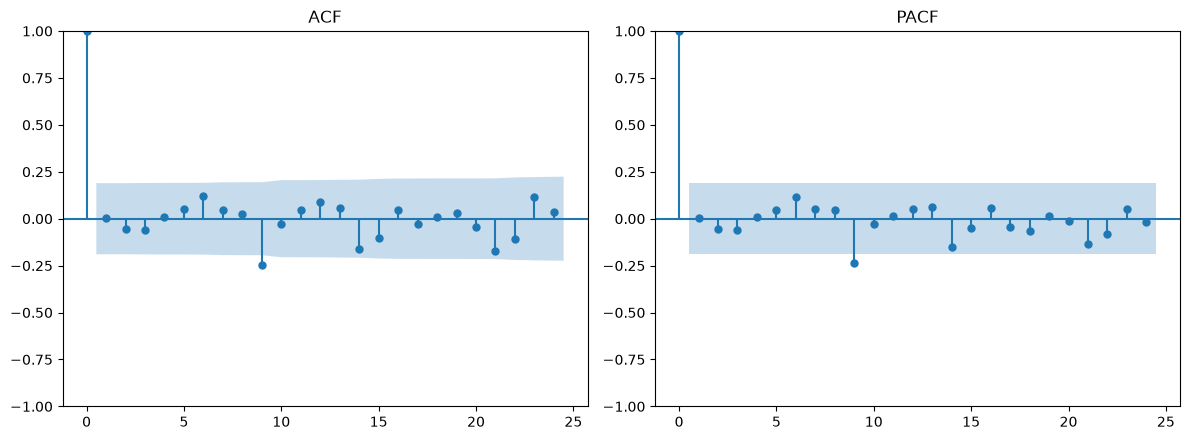

In [79]:
# ACF / PACF correlogram of the excess returns
fig, axes = plt.subplots(1, 2, figsize = (12, 4.5))
plot_acf(train, lags = 24, ax = axes[0])
plot_pacf(train, lags = 24, ax = axes[1])
axes[0].set_title("ACF")
axes[1].set_title("PACF")
plt.tight_layout()
plt.savefig("results/correlogram_ACF_PACF.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.5 Selecting the (p, q) orders with AIC / BIC

In [80]:
grid_results = []
for p, q in itertools.product(range(4), range(4)):
    try:
        fit = ARIMA(train, order=(p, 0, q)).fit()
        grid_results.append((p, q, fit.aic, fit.bic))
    except Exception:
        continue

order_table = pd.DataFrame(grid_results, columns=["p", "q", "AIC", "BIC"])
best_aic = order_table.loc[order_table["AIC"].idxmin()]
best_bic = order_table.loc[order_table["BIC"].idxmin()]

print("Best order according to AIC:", (int(best_aic.p), int(best_aic.q)),
      f"(AIC={best_aic.AIC:.2f})")
print("Best order according to BIC:", (int(best_bic.p), int(best_bic.q)),
      f"(BIC={best_bic.BIC:.2f})")
order_table.sort_values("BIC").head(6)

c:\Users\justi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\justi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\justi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\justi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\justi\AppData\Local\Programs\Python\Python314\

Best order according to AIC: (2, 2) (AIC=-595.21)
Best order according to BIC: (0, 0) (BIC=-588.53)


c:\Users\justi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,p,q,AIC,BIC
0,0,0,-593.877404,-588.531747
4,1,0,-591.881727,-583.863240
1,0,1,-591.880898,-583.862412
8,2,0,-590.254671,-579.563356
2,0,2,-590.237592,-579.546276
10,2,2,-595.205941,-579.168968


# 11. Forecast and confidence intervals

In [81]:
# Final estimation (order selected with BIC) and forecast
p_opt, q_opt = int(best_bic.p), int(best_bic.q)
final_model = ARIMA(train, order=(p_opt, 0, q_opt)).fit()
print(final_model.summary())

forecast = final_model.get_forecast(steps=len(test))
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int(alpha=0.05)

                               SARIMAX Results                                
Dep. Variable:           Excess_PONAX   No. Observations:                  107
Model:                          ARIMA   Log Likelihood                 298.939
Date:                Mon, 19 Oct 2026   AIC                           -593.877
Time:                        12:29:53   BIC                           -588.532
Sample:                    02-28-2015   HQIC                          -591.710
                         - 12-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0020      0.002      1.145      0.252      -0.001       0.005
sigma2         0.0002   1.49e-05     14.678      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   0.00   Jarque-

# 12. Graphical comparison and error metrics

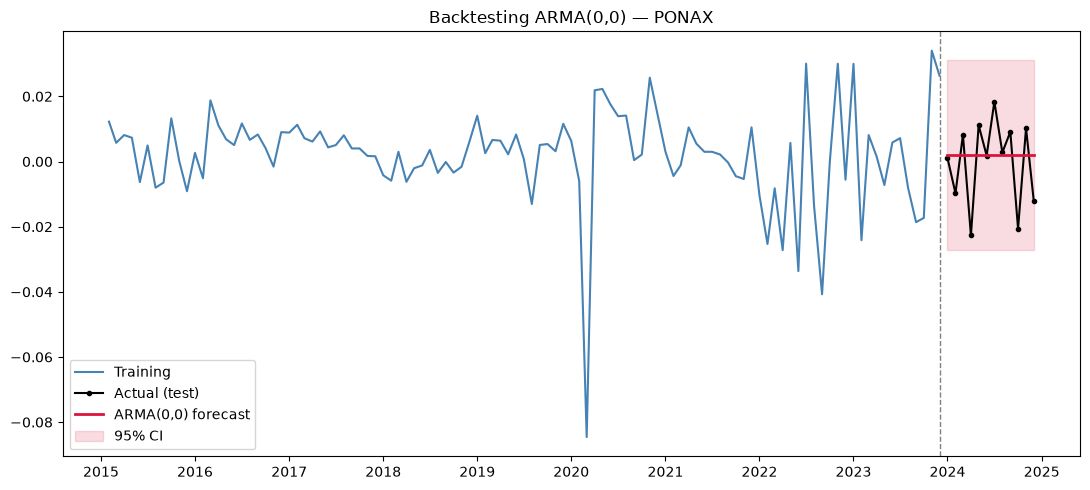

      ARMA(0,0)  Naive (historical mean)
RMSE    0.01280                  0.01280
MAE     0.01017                  0.01017

=> The ARMA model and the naive forecast have the same error: the model adds no predictive value.


In [82]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    train.index.to_timestamp(),
    train.values,
    label="Training",
    color="steelblue"
)

ax.plot(
    test.index.to_timestamp(),
    test.values,
    label="Actual (test)",
    color="black",
    marker="o",
    ms=3
)

ax.plot(
    test.index.to_timestamp(),
    forecast_mean.values,
    label=f"ARMA({p_opt},{q_opt}) forecast",
    color="crimson",
    lw=2
)

ax.fill_between(
    test.index.to_timestamp(),
    forecast_ci.iloc[:, 0].values,
    forecast_ci.iloc[:, 1].values,
    color="crimson",
    alpha=0.15,
    label="95% CI"
)

ax.axvline(
    train.index[-1].to_timestamp(),
    color="grey",
    ls="--",
    lw=1
)

ax.legend()
ax.set_title(f"Backtesting ARMA({p_opt},{q_opt}) — PONAX")
plt.tight_layout()
plt.savefig("results/backtesting_ARMA(0,0).png", dpi=300, bbox_inches="tight")
plt.show()

rmse_model = np.sqrt(np.mean((test.values - forecast_mean.values) ** 2))
mae_model = np.mean(np.abs(test.values - forecast_mean.values))

naive_forecast = np.full(len(test), train.mean())
rmse_naive = np.sqrt(np.mean((test.values - naive_forecast) ** 2))
mae_naive = np.mean(np.abs(test.values - naive_forecast))

error_table = pd.DataFrame({
    f"ARMA({p_opt},{q_opt})": [rmse_model, mae_model],
    "Naive (historical mean)": [rmse_naive, mae_naive],
}, index=["RMSE", "MAE"])
print(error_table.round(5))

# Comparison with a tolerance: a relative gap below 0.1% between the two RMSEs is treated as equality
# (a strict "<" comparison between two nearly equal floats can wrongly conclude that the model adds value)
if np.isclose(rmse_model, rmse_naive, rtol = 1e-3):
    print("\n=> The ARMA model and the naive forecast have the same error: the model adds no predictive value.")
elif rmse_model < rmse_naive:
    print("\n=> The ARMA model adds predictive value compared with the naive forecast.")
else:
    print("\n=> The ARMA model does NOT beat the naive forecast on this test sample: this must be discussed, not hidden.")